# Eksploracja danych rynkowych

## Financial Decision Support System

Notebook dokumentuje jakość, zakres i właściwości danych przygotowanych przez
produkcyjny pipeline systemu wspomagania decyzji finansowych. Nie pobiera danych
z internetu, nie tworzy nowych zbiorów i nie powiela logiki przetwarzania
zaimplementowanej w backendzie.

Analiza służy do:

- potwierdzenia kontraktu danych;
- opisania ośmiu analizowanych instrumentów;
- zbadania treningowych stóp zwrotu, zmienności i korelacji;
- oceny cech wejściowych przed budową modeli prognostycznych.

## Zasada zamkniętego zbioru testowego

Wszystkie statystyki, wykresy i wnioski analityczne w tym notebooku powstają
wyłącznie na zbiorze treningowym. Informacje o walidacji i teście pochodzą jedynie
z manifestu danych i ograniczają się do liczby obserwacji oraz zakresów dat.

Zbiór walidacyjny służy do porównywania modeli, natomiast zbiór testowy pozostaje
zamknięty do finalnej, jednorazowej ewaluacji projektu. Takie rozdzielenie
ogranicza ryzyko dopasowania decyzji analitycznych do przyszłych obserwacji.

In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.container import BarContainer

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.6f}")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titleweight"] = "bold"

## Lokalizacja projektu i artefaktów danych

Katalog projektu jest wykrywany na podstawie obecności folderów `backend` i
`data`. Dzięki temu notebook działa zarówno po uruchomieniu z katalogu głównego,
jak i bezpośrednio z folderu `notebooks`.

In [2]:
def find_project_root(start_directory: Path) -> Path:
    candidates = (start_directory, *start_directory.parents)

    for candidate in candidates:
        if (candidate / "backend").is_dir() and (candidate / "data").is_dir():
            return candidate

    raise FileNotFoundError(
        "Nie znaleziono katalogu głównego projektu zawierającego backend/ i data/."
    )


PROJECT_ROOT = find_project_root(Path.cwd().resolve())

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from backend.src.config import (
    MARKET_DATASETS_DIR,
    SUPPORTED_TICKERS,
    TRAIN_DATASET_FILENAME,
)

TRAIN_DATASET_PATH = MARKET_DATASETS_DIR / TRAIN_DATASET_FILENAME
MANIFEST_PATH = MARKET_DATASETS_DIR / "manifest.json"

required_artifacts = (TRAIN_DATASET_PATH, MANIFEST_PATH)
missing_artifacts = [path for path in required_artifacts if not path.is_file()]

if missing_artifacts:
    missing_text = ", ".join(str(path) for path in missing_artifacts)
    raise FileNotFoundError(
        "Brakuje artefaktów pipeline'u danych. Uruchom najpierw "
        f"`python3 -m backend.src.data_cli`. Braki: {missing_text}"
    )

print(f"Project root: {PROJECT_ROOT}")
print(f"Training dataset: {TRAIN_DATASET_PATH}")
print(f"Data manifest: {MANIFEST_PATH}")

Project root: project-root
Training dataset: data/datasets/market/train.csv
Data manifest: data/datasets/market/manifest.json


## Wczytanie manifestu i zbioru treningowego

Manifest stanowi zapis parametrów oraz wyników reprodukowalnego pipeline'u.
Notebook nie otwiera plików walidacyjnych ani testowych na potrzeby eksploracji.

In [3]:
manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))

training_dataset = pd.read_csv(
    TRAIN_DATASET_PATH,
    parse_dates=["date", "target_date"],
)

print(f"Wiersze treningowe: {len(training_dataset):,}")
print(f"Liczba tickerów: {training_dataset['ticker'].nunique()}")
print(f"Liczba kolumn: {training_dataset.shape[1]}")

Wiersze treningowe: 23,680
Liczba tickerów: 8
Liczba kolumn: 20


In [4]:
request_summary = pd.DataFrame(
    {
        "parameter": [
            "start_date",
            "end_date_exclusive",
            "interval",
            "minimum_observations_per_ticker",
            "tickers",
        ],
        "value": [
            manifest["request"]["start_date"],
            manifest["request"]["end_date_exclusive"],
            manifest["request"]["interval"],
            manifest["request"]["minimum_observations_per_ticker"],
            ", ".join(manifest["request"]["tickers"]),
        ],
    }
)

request_summary

,parameter,value
0,start_date,2010-01-01
1,end_date_exclusive,2026-08-01
2,interval,1d
3,minimum_observations_per_ticker,1000
4,tickers,"EPOL, VGK, SPY, VT, QQQ, GLD, BTC-USD, AGG"


## Zakres przygotowanych zbiorów

Poniższe informacje pochodzą z manifestu. Daty cech opisują moment dostępności
informacji wejściowych, natomiast daty targetów wskazują sesję, której zwrot jest
prognozowany.

In [5]:
dataset_rows = []

for dataset_name, summary in manifest["outputs"].items():
    dataset_rows.append(
        {
            "dataset": dataset_name,
            "rows": summary["rows"],
            "feature_date_min": summary["date_min"],
            "feature_date_max": summary["date_max"],
            "target_date_min": summary.get("target_date_min"),
            "target_date_max": summary.get("target_date_max"),
        }
    )

dataset_summary = pd.DataFrame(dataset_rows)
dataset_summary

,dataset,rows,feature_date_min,feature_date_max,target_date_min,target_date_max
0,processed,33260,2010-02-02,2026-07-31,NaN,NaN
1,train,23680,2010-02-02,2022-01-24,2010-02-03,2022-01-25
2,validation,4786,2022-01-25,2024-04-27,2022-01-26,2024-04-28
3,test,4786,2024-04-26,2026-07-30,2024-04-29,2026-07-31


## Kontrakt i integralność zbioru treningowego

Kontrola obejmuje wymagane kolumny, typy dat, kompletność, skończoność wartości
numerycznych, unikalność par ticker–data oraz chronologię targetu. Są to testy
artefaktu wyjściowego, a nie ponowna implementacja czyszczenia danych.

In [6]:
EXPECTED_COLUMNS = (
    "date",
    "ticker",
    "open",
    "high",
    "low",
    "close",
    "adjusted_close",
    "volume",
    "daily_return",
    "log_return",
    "price_change",
    "volume_change",
    "moving_average_5",
    "moving_average_20",
    "volatility_5",
    "volatility_20",
    "momentum_5",
    "momentum_20",
    "target_date",
    "target",
)

missing_columns = sorted(set(EXPECTED_COLUMNS) - set(training_dataset.columns))
unexpected_columns = sorted(set(training_dataset.columns) - set(EXPECTED_COLUMNS))
numeric_columns = training_dataset.select_dtypes(include="number").columns.tolist()

numeric_values = np.asarray(
    training_dataset[numeric_columns],
    dtype=float,
)

integrity_summary = pd.DataFrame(
    [
        {
            "check": "missing_required_columns",
            "result": len(missing_columns),
            "details": ", ".join(missing_columns) or "none",
        },
        {
            "check": "unexpected_columns",
            "result": len(unexpected_columns),
            "details": ", ".join(unexpected_columns) or "none",
        },
        {
            "check": "missing_values",
            "result": int(training_dataset.isna().sum().sum()),
            "details": "all columns",
        },
        {
            "check": "infinite_numeric_values",
            "result": int(np.isinf(numeric_values).sum()),
            "details": "numeric columns",
        },
        {
            "check": "duplicate_ticker_dates",
            "result": int(training_dataset.duplicated(["ticker", "date"]).sum()),
            "details": "ticker + feature date",
        },
        {
            "check": "non_future_target_dates",
            "result": int(
                (training_dataset["target_date"] <= training_dataset["date"]).sum()
            ),
            "details": "target_date must be later than date",
        },
    ]
)

integrity_summary

,check,result,details
0,missing_required_columns,0,none
1,unexpected_columns,0,none
2,missing_values,0,all columns
3,infinite_numeric_values,0,numeric columns
4,duplicate_ticker_dates,0,ticker + feature date
5,non_future_target_dates,0,target_date must be later than date


In [7]:
assert not missing_columns
assert not unexpected_columns
assert training_dataset.isna().sum().sum() == 0
assert np.isfinite(numeric_values).all()
assert not training_dataset.duplicated(["ticker", "date"]).any()
assert (training_dataset["target_date"] > training_dataset["date"]).all()
assert set(training_dataset["ticker"]) == set(SUPPORTED_TICKERS)
assert len(training_dataset) == manifest["outputs"]["train"]["rows"]

print("Integralność zbioru treningowego: OK")

Integralność zbioru treningowego: OK


## Pokrycie danych według instrumentu

Instrumenty mają różne początki historii, ale wszystkie spełniają minimalny próg
obserwacji. Zachowanie danych w układzie długim pozwala każdemu instrumentowi
korzystać z własnego kalendarza notowań.

In [8]:
coverage_by_ticker = (
    training_dataset.groupby("ticker", sort=True)
    .agg(
        observations=("target", "size"),
        feature_date_min=("date", "min"),
        feature_date_max=("date", "max"),
        target_date_min=("target_date", "min"),
        target_date_max=("target_date", "max"),
    )
    .sort_index()
)

coverage_by_ticker

,observations,feature_date_min,feature_date_max,target_date_min,target_date_max
ticker,,,,,
AGG,3016,2010-02-02,2022-01-24,2010-02-03,2022-01-25
BTC-USD,2667,2014-10-07,2022-01-24,2014-10-08,2022-01-25
EPOL,2917,2010-06-24,2022-01-24,2010-06-25,2022-01-25
GLD,3016,2010-02-02,2022-01-24,2010-02-03,2022-01-25
QQQ,3016,2010-02-02,2022-01-24,2010-02-03,2022-01-25
SPY,3016,2010-02-02,2022-01-24,2010-02-03,2022-01-25
VGK,3016,2010-02-02,2022-01-24,2010-02-03,2022-01-25
VT,3016,2010-02-02,2022-01-24,2010-02-03,2022-01-25


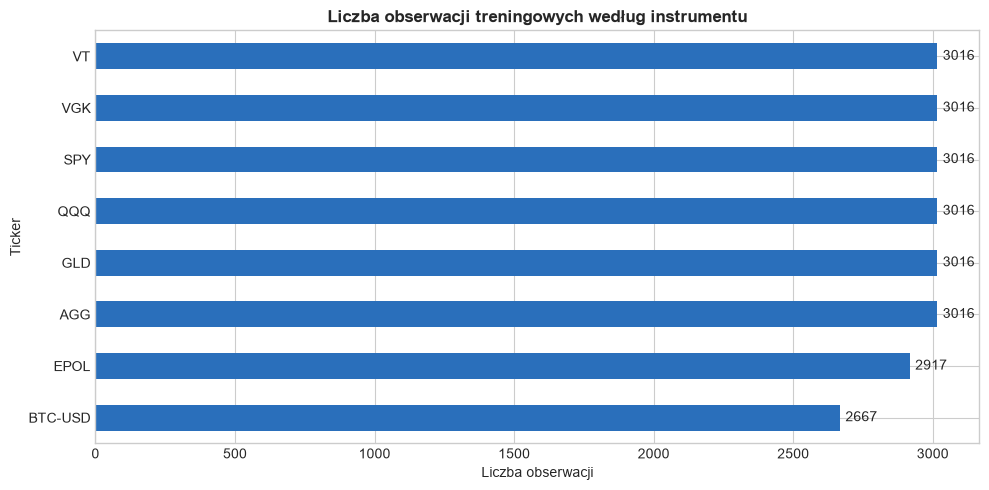

In [9]:
ax = (
    coverage_by_ticker["observations"]
    .sort_values()
    .plot.barh(
        color="#2A6FBB",
        figsize=(10, 5),
    )
)

ax.set_title("Liczba obserwacji treningowych według instrumentu")
ax.set_xlabel("Liczba obserwacji")
ax.set_ylabel("Ticker")

for container in ax.containers:
    if isinstance(container, BarContainer):
        ax.bar_label(
            container,
            padding=4,
            fmt="%d",
        )

plt.tight_layout()
plt.show()

## Znormalizowane ceny w zbiorze treningowym

Ceny są normalizowane oddzielnie dla każdego instrumentu do wartości 100 w jego
pierwszej dostępnej obserwacji. Panel jest budowany przez `pivot`, dzięki czemu
nie przejmuje przypadkowo kalendarza pierwszego instrumentu. Skala logarytmiczna
umożliwia czytelne porównanie aktywów o bardzo różnej dynamice.

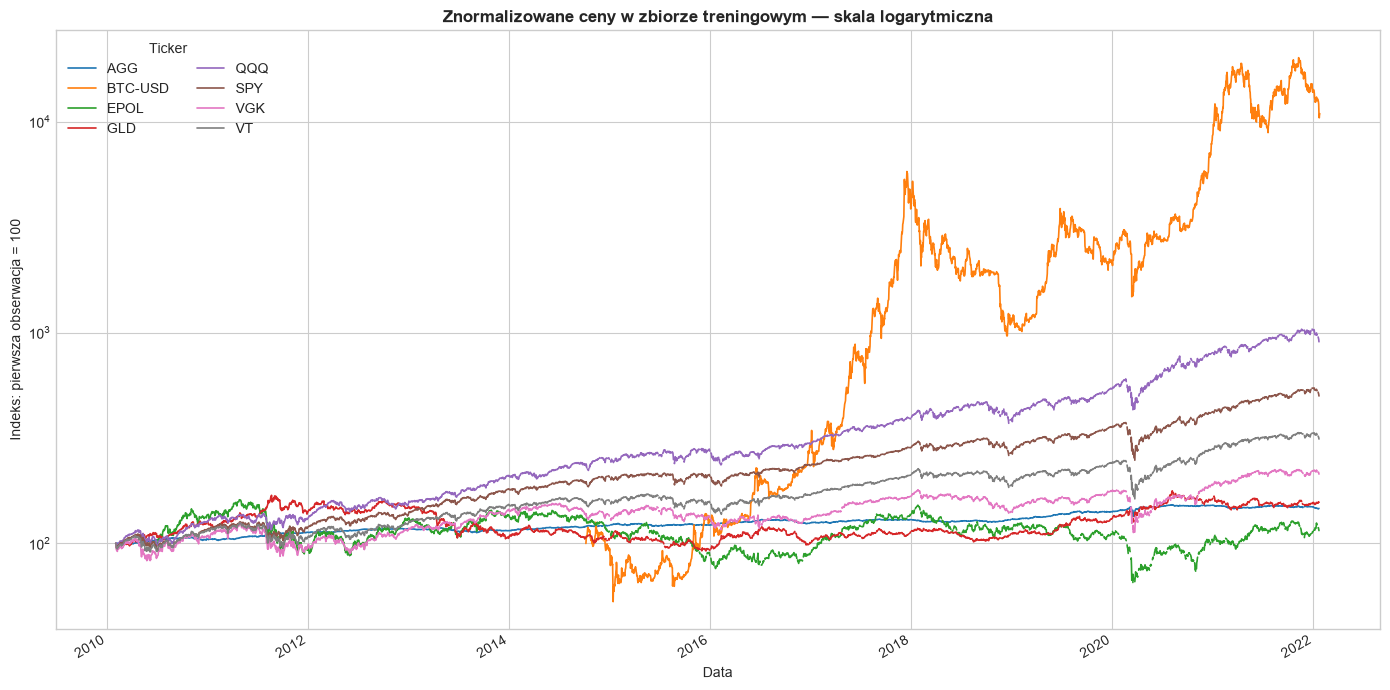

In [10]:
adjusted_close_panel = training_dataset.pivot(
    index="date",
    columns="ticker",
    values="adjusted_close",
).sort_index()

normalized_prices = adjusted_close_panel.apply(
    lambda series: series / series.dropna().iloc[0] * 100.0
)

ax = normalized_prices.plot(
    logy=True,
    linewidth=1.2,
    figsize=(14, 7),
)
ax.set_title("Znormalizowane ceny w zbiorze treningowym — skala logarytmiczna")
ax.set_xlabel("Data")
ax.set_ylabel("Indeks: pierwsza obserwacja = 100")
ax.legend(title="Ticker", ncol=2)
plt.tight_layout()
plt.show()

## Rozkład prognozowanej stopy zwrotu

Zmienna `target` oznacza prostą stopę zwrotu w następnej sesji danego
instrumentu. Poniższe statystyki i wykresy wykorzystują wyłącznie trening.
Udział dodatnich obserwacji pomaga ocenić równowagę kierunków zmian, natomiast
kwantyle pokazują skalę ogonów rozkładu.

In [11]:
target_statistics = training_dataset.groupby("ticker", sort=True)["target"].agg(
    observations="size",
    mean="mean",
    median="median",
    standard_deviation="std",
    minimum="min",
    maximum="max",
)

target_statistics["q01"] = training_dataset.groupby("ticker")["target"].quantile(0.01)
target_statistics["q05"] = training_dataset.groupby("ticker")["target"].quantile(0.05)
target_statistics["q95"] = training_dataset.groupby("ticker")["target"].quantile(0.95)
target_statistics["q99"] = training_dataset.groupby("ticker")["target"].quantile(0.99)
target_statistics["positive_share"] = training_dataset.groupby("ticker")["target"].agg(
    lambda values: float((values > 0.0).mean())
)
target_statistics["zero_share"] = training_dataset.groupby("ticker")["target"].agg(
    lambda values: float((values == 0.0).mean())
)

target_statistics

,observations,mean,median,standard_deviation,minimum,maximum,q01,q05,q95,q99,positive_share,zero_share
ticker,,,,,,,,,,,,
AGG,3016,0.000129,0.000185,0.002496,-0.040011,0.023721,-0.005595,-0.003296,0.003318,0.005388,0.537135,0.017241
BTC-USD,2667,0.002525,0.002022,0.038844,-0.371695,0.252472,-0.106307,-0.059986,0.064229,0.113561,0.543307,0.000375
EPOL,2917,0.000183,0.000684,0.017304,-0.137441,0.092518,-0.045368,-0.025569,0.026451,0.042338,0.512856,0.011999
GLD,3016,0.000201,0.000433,0.009881,-0.087808,0.049038,-0.027281,-0.015893,0.015226,0.025846,0.523210,0.003979
QQQ,3016,0.000800,0.001261,0.012334,-0.119788,0.084705,-0.034723,-0.019662,0.018491,0.031490,0.563992,0.004973
SPY,3016,0.000588,0.000716,0.010674,-0.109424,0.090603,-0.030354,-0.016236,0.014882,0.027307,0.557692,0.003316
VGK,3016,0.000335,0.000723,0.013478,-0.117782,0.090566,-0.038076,-0.020540,0.018735,0.034535,0.534814,0.005968
VT,3016,0.000437,0.000795,0.011145,-0.116411,0.091410,-0.030988,-0.017162,0.015811,0.027432,0.544761,0.009947


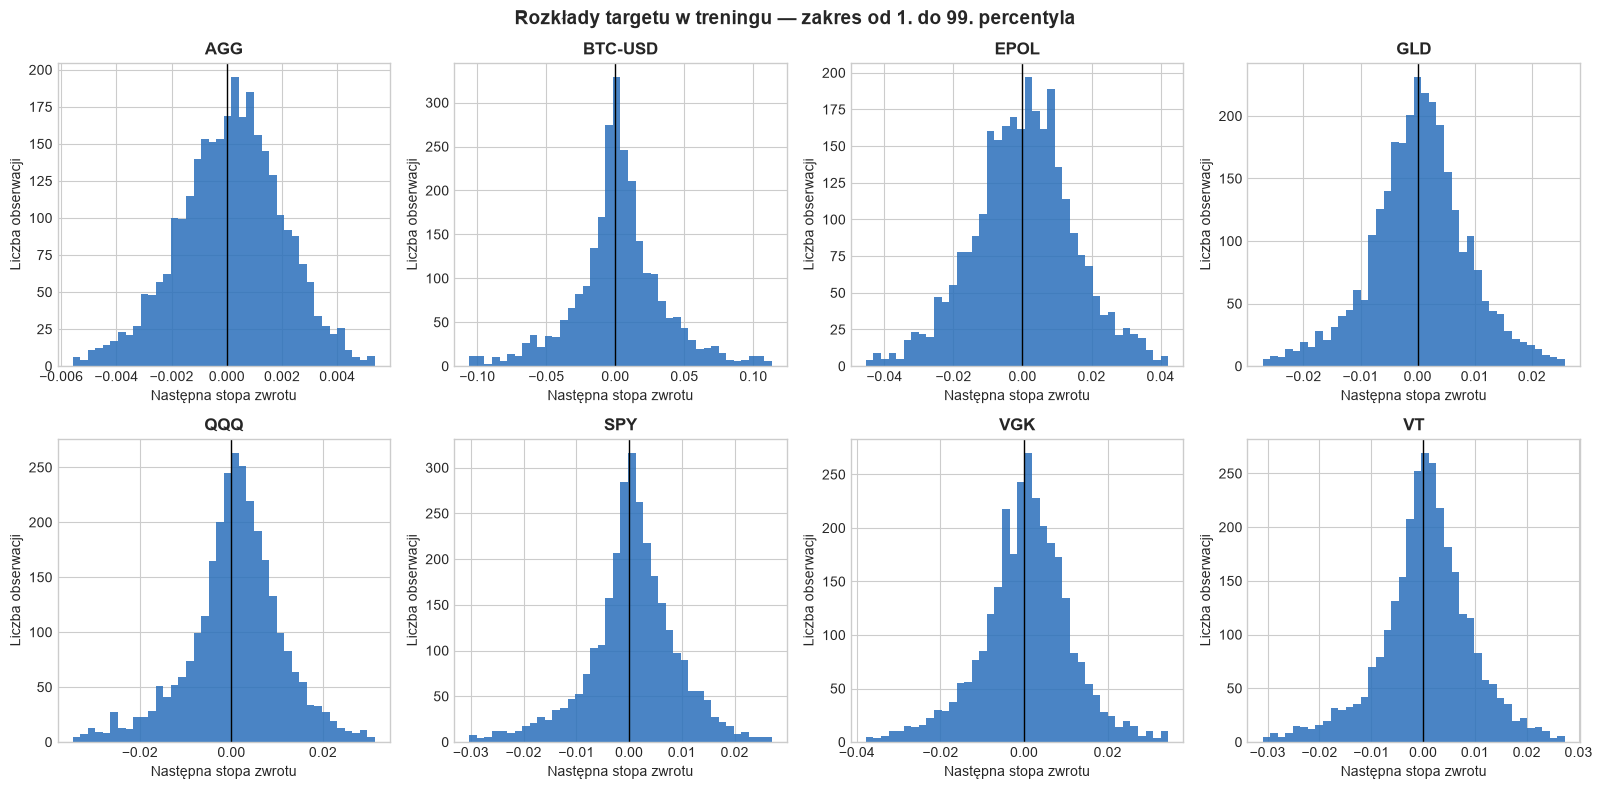

In [12]:
tickers = sorted(training_dataset["ticker"].astype(str).unique().tolist())

figure, axes = plt.subplots(
    2,
    4,
    figsize=(16, 8),
    sharey=False,
)

for ticker, axis in zip(
    tickers,
    axes.ravel(),
    strict=True,
):
    ticker_target_values = np.asarray(
        training_dataset.loc[
            training_dataset["ticker"] == ticker,
            "target",
        ],
        dtype=float,
    )

    lower_bound, upper_bound = np.quantile(
        ticker_target_values,
        [0.01, 0.99],
    )

    central_target_values = ticker_target_values[
        (ticker_target_values >= lower_bound) & (ticker_target_values <= upper_bound)
    ]

    axis.hist(
        central_target_values,
        bins=40,
        color="#2A6FBB",
        alpha=0.85,
    )
    axis.axvline(
        0.0,
        color="black",
        linewidth=1.0,
    )
    axis.set_title(ticker)
    axis.set_xlabel("Następna stopa zwrotu")
    axis.set_ylabel("Liczba obserwacji")

figure.suptitle(
    "Rozkłady targetu w treningu — zakres od 1. do 99. percentyla",
    fontsize=14,
    fontweight="bold",
)

figure.tight_layout()
plt.show()

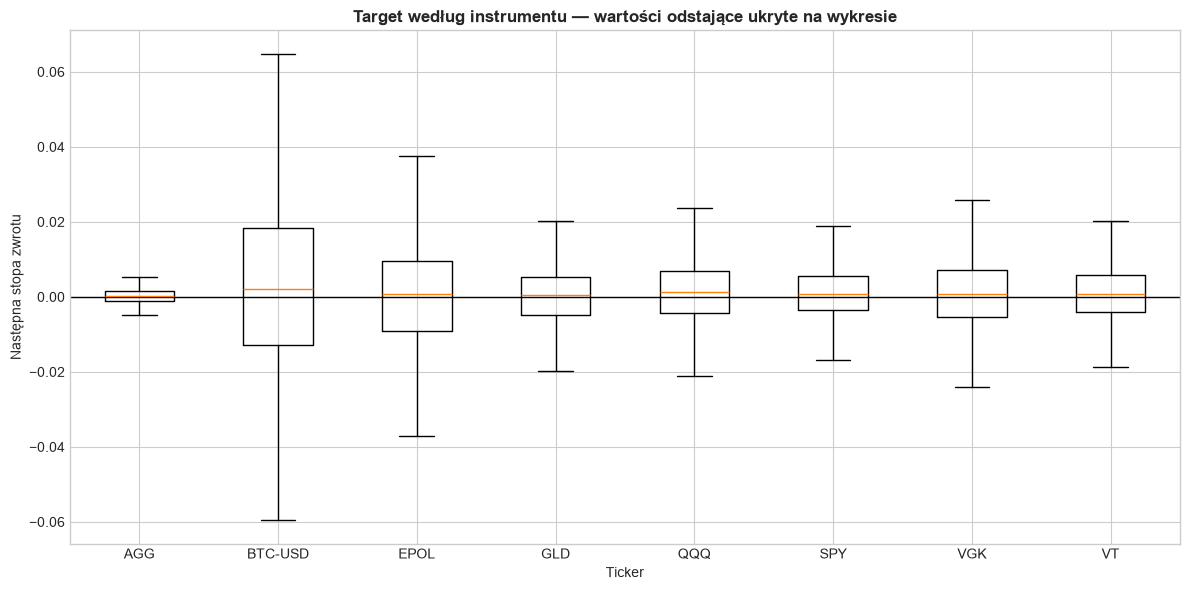

In [13]:
figure, axis = plt.subplots(figsize=(12, 6))

target_arrays = [
    np.asarray(
        training_dataset.loc[
            training_dataset["ticker"] == ticker,
            "target",
        ],
        dtype=float,
    )
    for ticker in tickers
]

axis.boxplot(
    target_arrays,
    tick_labels=tickers,
    showfliers=False,
)

axis.axhline(
    0.0,
    color="black",
    linewidth=1.0,
)

axis.set_title("Target według instrumentu — wartości odstające ukryte na wykresie")
axis.set_xlabel("Ticker")
axis.set_ylabel("Następna stopa zwrotu")

plt.tight_layout()
plt.show()

## Zmienność w czasie

Zmienność jest liczona jako kroczące odchylenie standardowe ostatnich 20
obserwacji targetu oddzielnie dla każdego instrumentu. Nie jest annualizowana,
dzięki czemu nie narzucamy Bitcoinowi kalendarza 252 sesji giełdowych.

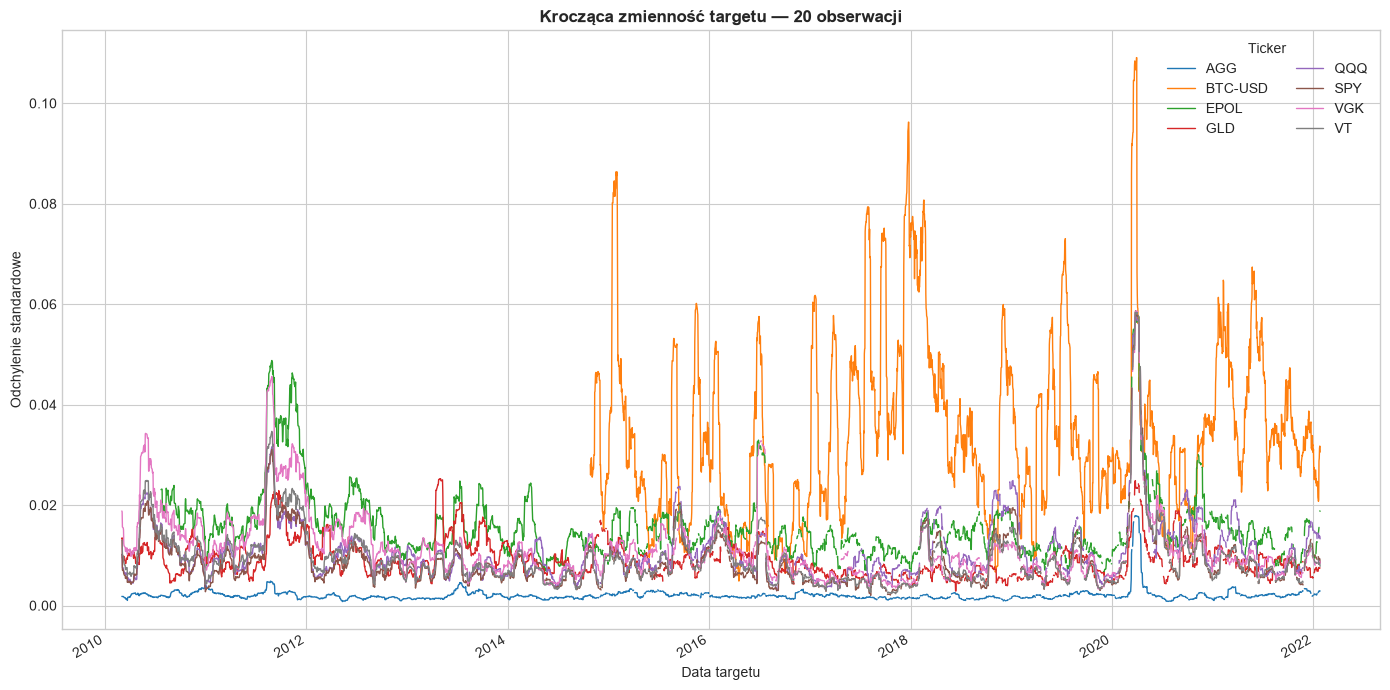

In [14]:
ordered_training = training_dataset.sort_values(["ticker", "target_date"]).copy()
ordered_training["rolling_volatility_20"] = ordered_training.groupby("ticker")[
    "target"
].transform(lambda values: values.rolling(window=20, min_periods=20).std())

rolling_volatility_panel = ordered_training.pivot(
    index="target_date",
    columns="ticker",
    values="rolling_volatility_20",
)

ax = rolling_volatility_panel.plot(
    linewidth=1.0,
    figsize=(14, 7),
)
ax.set_title("Krocząca zmienność targetu — 20 obserwacji")
ax.set_xlabel("Data targetu")
ax.set_ylabel("Odchylenie standardowe")
ax.legend(title="Ticker", ncol=2)
plt.tight_layout()
plt.show()

## Korelacje pomiędzy klasami aktywów

Do macierzy korelacji wykorzystujemy wyłącznie daty targetów obecne dla
wszystkich instrumentów. Zapewnia to jeden jawny, wspólny zakres obserwacji
zamiast korelacji liczonych na różnych parach dat.

In [15]:
target_panel = training_dataset.pivot(
    index="target_date",
    columns="ticker",
    values="target",
).sort_index()

common_target_panel = target_panel.dropna(how="any")

if common_target_panel.empty:
    raise ValueError("Brak wspólnych dat targetów dla wszystkich instrumentów.")

correlation_matrix = common_target_panel.corr()

print(f"Wspólne daty wykorzystane w korelacji: {len(common_target_panel):,}")
correlation_matrix

Wspólne daty wykorzystane w korelacji: 1,838


ticker,AGG,BTC-USD,EPOL,GLD,QQQ,SPY,VGK,VT
ticker,,,,,,,,
AGG,1.000000,0.108199,0.043539,0.344677,0.005273,-0.008617,0.037855,0.016986
BTC-USD,0.108199,1.000000,0.127327,0.086894,0.168061,0.162545,0.159176,0.168930
EPOL,0.043539,0.127327,1.000000,0.153931,0.563250,0.621756,0.740386,0.698723
GLD,0.344677,0.086894,0.153931,1.000000,0.015252,-0.005835,0.061746,0.035097
QQQ,0.005273,0.168061,0.563250,0.015252,1.000000,0.920928,0.733623,0.885782
SPY,-0.008617,0.162545,0.621756,-0.005835,0.920928,1.000000,0.840495,0.971643
VGK,0.037855,0.159176,0.740386,0.061746,0.733623,0.840495,1.000000,0.922014
VT,0.016986,0.168930,0.698723,0.035097,0.885782,0.971643,0.922014,1.000000


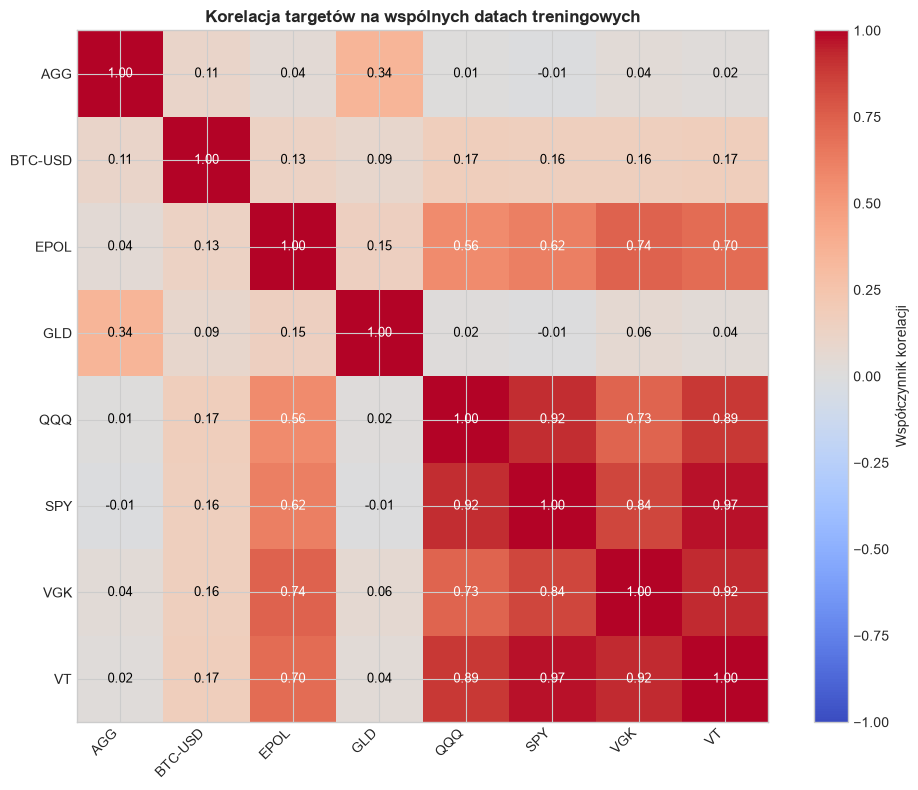

In [16]:
correlation_values = np.asarray(
    correlation_matrix,
    dtype=float,
)

correlation_labels = correlation_matrix.columns.astype(str).tolist()

figure, axis = plt.subplots(figsize=(10, 8))

image = axis.imshow(
    correlation_values,
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
)

axis.set_xticks(range(len(correlation_labels)))
axis.set_xticklabels(
    correlation_labels,
    rotation=45,
    ha="right",
)
axis.set_yticks(range(len(correlation_labels)))
axis.set_yticklabels(correlation_labels)

axis.set_title("Korelacja targetów na wspólnych datach treningowych")

for row_index in range(len(correlation_labels)):
    for column_index in range(len(correlation_labels)):
        correlation_value = float(
            correlation_values[
                row_index,
                column_index,
            ]
        )

        text_color = "white" if abs(correlation_value) > 0.55 else "black"

        axis.text(
            column_index,
            row_index,
            f"{correlation_value:.2f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=9,
        )

figure.colorbar(
    image,
    ax=axis,
    label="Współczynnik korelacji",
)

figure.tight_layout()
plt.show()

## Jakość i informacyjność cech wejściowych

Poniższa tabela opisuje kolumny dostępne przed transformacją cech przez model
Random Forest. Korelacja rang Spearmana z targetem jest wyłącznie miarą
jednowymiarowej zależności w treningu — nie dowodzi związku przyczynowego i nie
zastępuje walidacji modelu ani analiz SHAP, PDP i ALE.

In [17]:
NON_FEATURE_COLUMNS = {"date", "ticker", "target_date", "target"}
feature_columns = [
    column for column in training_dataset.columns if column not in NON_FEATURE_COLUMNS
]

feature_audit = pd.DataFrame(
    {
        "dtype": training_dataset[feature_columns].dtypes.astype(str),
        "unique_values": training_dataset[feature_columns].nunique(dropna=False),
        "missing_values": training_dataset[feature_columns].isna().sum(),
        "minimum": training_dataset[feature_columns].min(),
        "median": training_dataset[feature_columns].median(),
        "maximum": training_dataset[feature_columns].max(),
    }
)

feature_audit

,dtype,unique_values,missing_values,minimum,median,maximum
open,float64,14229,0,12.110000,108.989998,"67,549.734375"
high,float64,14210,0,12.750000,109.180000,"68,789.625000"
low,float64,14160,0,12.110000,108.779999,"66,382.062500"
close,float64,14161,0,12.430000,109.005001,"67,566.828125"
adjusted_close,float64,21689,0,10.211895,84.124416,"67,566.828125"
volume,int64,21420,0,"2,000.000000","5,914,200.000000","350,967,941,479.000000"
daily_return,float64,23494,0,-0.371695,0.000600,0.252472
log_return,float64,23494,0,-0.464730,0.000599,0.225119
price_change,float64,21446,0,"-7,554.039062",0.040001,"7,293.023438"
volume_change,float64,23666,0,-0.982759,-0.011459,56.858696


In [18]:
spearman_target_correlation = (
    training_dataset[[*feature_columns, "target"]]
    .corr(method="spearman")["target"]
    .drop("target")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)

spearman_target_correlation.to_frame("spearman_correlation_with_target")

,spearman_correlation_with_target
volatility_5,0.057194
volatility_20,0.052136
daily_return,-0.044236
log_return,-0.044236
price_change,-0.041284
volume,0.032793
momentum_5,-0.018699
moving_average_20,0.018370
moving_average_5,0.017860
adjusted_close,0.017385


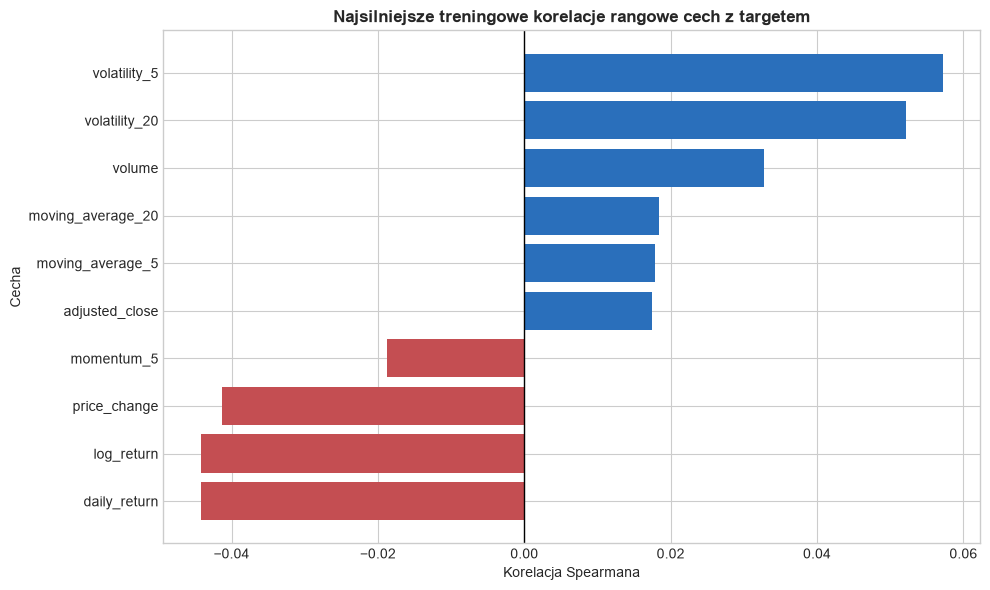

In [19]:
top_feature_correlations = spearman_target_correlation.head(10).sort_values()

top_feature_labels = top_feature_correlations.index.astype(str).tolist()

top_feature_correlation_values = np.asarray(
    top_feature_correlations,
    dtype=float,
)

top_feature_bar_colors = [
    "#C44E52" if feature_correlation < 0.0 else "#2A6FBB"
    for feature_correlation in top_feature_correlation_values
]

figure, axis = plt.subplots(figsize=(10, 6))

axis.barh(
    top_feature_labels,
    top_feature_correlation_values,
    color=top_feature_bar_colors,
)

axis.axvline(
    0.0,
    color="black",
    linewidth=1.0,
)

axis.set_title("Najsilniejsze treningowe korelacje rangowe cech z targetem")
axis.set_xlabel("Korelacja Spearmana")
axis.set_ylabel("Cecha")

figure.tight_layout()
plt.show()

## Automatyczne podsumowanie eksploracji

Komórka poniżej wskazuje najważniejsze właściwości treningu bez wprowadzania
ręcznie wpisanych wartości, które mogłyby zdezaktualizować się po ponownym
uruchomieniu pipeline'u.

In [20]:
volatility_values = np.asarray(
    target_statistics["standard_deviation"],
    dtype=float,
)

volatility_labels = target_statistics.index.astype(str).tolist()

highest_volatility_position = int(np.argmax(volatility_values))
lowest_volatility_position = int(np.argmin(volatility_values))

highest_volatility_ticker = volatility_labels[highest_volatility_position]
lowest_volatility_ticker = volatility_labels[lowest_volatility_position]

highest_volatility_value = float(volatility_values[highest_volatility_position])
lowest_volatility_value = float(volatility_values[lowest_volatility_position])

asset_correlation_values = np.asarray(
    correlation_matrix,
    dtype=float,
)

asset_correlation_labels = correlation_matrix.columns.astype(str).tolist()

upper_triangle = np.triu(
    np.ones_like(
        asset_correlation_values,
        dtype=bool,
    ),
    k=1,
)

eligible_asset_correlations = np.where(
    upper_triangle,
    asset_correlation_values,
    np.nan,
)

strongest_flat_position = int(np.nanargmax(eligible_asset_correlations))

strongest_row, strongest_column = np.unravel_index(
    strongest_flat_position,
    eligible_asset_correlations.shape,
)

strongest_pair = (
    asset_correlation_labels[strongest_row],
    asset_correlation_labels[strongest_column],
)

strongest_pair_value = float(
    eligible_asset_correlations[
        strongest_row,
        strongest_column,
    ]
)

spearman_values = np.asarray(
    spearman_target_correlation,
    dtype=float,
)

strongest_feature_name = str(spearman_target_correlation.index[0])

strongest_feature_value = float(spearman_values[0])

print("Najważniejsze obserwacje z treningu:")

print(
    "  Najwyższa zmienność targetu: "
    f"{highest_volatility_ticker} "
    f"({highest_volatility_value:.6f})"
)

print(
    "  Najniższa zmienność targetu: "
    f"{lowest_volatility_ticker} "
    f"({lowest_volatility_value:.6f})"
)

print(
    "  Najsilniejsza dodatnia korelacja na wspólnych datach: "
    f"{strongest_pair[0]}–{strongest_pair[1]} "
    f"({strongest_pair_value:.4f})"
)

print(
    "  Najsilniejsza bezwzględna korelacja rangowa cechy z targetem: "
    f"{strongest_feature_name} "
    f"({strongest_feature_value:.4f})"
)

Najważniejsze obserwacje z treningu:
  Najwyższa zmienność targetu: BTC-USD (0.038844)
  Najniższa zmienność targetu: AGG (0.002496)
  Najsilniejsza dodatnia korelacja na wspólnych datach: SPY–VT (0.9716)
  Najsilniejsza bezwzględna korelacja rangowa cechy z targetem: volatility_5 (0.0572)


## Wnioski i przekazanie do kolejnego etapu

- Pipeline dostarcza kompletny, skończony numerycznie i chronologicznie poprawny
  zbiór treningowy dla ośmiu klas aktywów.
- Różne początki historii i kalendarze notowań są zachowane w układzie długim.
- Rozkłady zwrotów różnią się skalą i obecnością wartości skrajnych, dlatego same
  średnie nie wystarczają do oceny ryzyka.
- Korelacje aktywów są liczone na jawnym wspólnym zbiorze dat i wskazują potencjał
  dywersyfikacji, ale nie są stałe w czasie.
- Jednowymiarowe zależności cech z targetem należy traktować jako opis danych,
  nie jako dowód jakości prognostycznej.

Kolejny notebook, `02_forecasting.ipynb`, porówna naiwny benchmark, ARIMA i Random
Forest na wydzielonym zbiorze walidacyjnym. Zbiór testowy pozostanie zamknięty do
finalnej ewaluacji.